In [1]:
# ============================================================
# EVALUATION EXPERIMENTS - REPRODUCIBLE PIPELINE (READ-ONLY)
# ============================================================
# This notebook strengthens the experimental evaluation WITHOUT touching
# the deployed artifacts. It NEVER writes to ../model/. The preprocessing
# and WQI definitions below are copied VERBATIM from notebooks/WqiPred.ipynb
# (cells 0 and 2) and are cross-checked against the shipped model so the
# evaluation provably runs on the same data/target the model was trained on.

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              StackingRegressor)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import sklearn
import shap

RANDOM_STATE = 42

# Authoritative 6-parameter list (identical to WqiPred.ipynb cell 0).
FEATURES = [
    "D.O. (mg/l)",
    "PH",
    "CONDUCTIVITY (\u00b5mhos/cm)",
    "B.O.D. (mg/l)",
    "NITRATENAN N+ NITRITENANN (mg/l)",
    "TOTAL COLIFORM (MPN/100ml)Mean",
]

df = pd.read_csv("../data/water_dataX.csv", encoding="latin1")
print("RAW rows:", len(df))

for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# pH corruption report: the raw pH maximum is a sensor/entry artifact, not water.
raw_ph = df["PH"]
print("RAW pH  -> min %.1f, max %.1f, NaN %d"
      % (raw_ph.min(), raw_ph.max(), int(raw_ph.isna().sum())))
print("RAW pH rows outside [0,14]:", int(((raw_ph < 0) | (raw_ph > 14)).sum()))

invalid_ph = (df["PH"] < 0) | (df["PH"] > 14)
n_raw = len(df)
df = df[~invalid_ph].copy()
n_ph = len(df)
df = df.drop_duplicates()                       # all columns identical
n_allcol = len(df)

model_df = df.dropna(subset=FEATURES).copy()
n_dropna = len(model_df)
rows_before = len(model_df)
model_df = model_df.drop_duplicates(subset=FEATURES)   # identical parameter vector

print("\nCleaning chain:")
print("  raw                  :", n_raw)
print("  - invalid pH        ->", n_ph)
print("  - all-col dupes     ->", n_allcol)
print("  - dropna(6 features)->", n_dropna, "(removed", n_allcol - n_dropna, ")")
print("  - feature-vector dup->", len(model_df), "(removed", rows_before - len(model_df), ")")
print("  FINAL N              :", len(model_df))

RAW rows: 1991
RAW pH  -> min 0.0, max 67115.0, NaN 8
RAW pH rows outside [0,14]: 89

Cleaning chain:
  raw                  : 1991
  - invalid pH        -> 1902
  - all-col dupes     -> 1901
  - dropna(6 features)-> 1594 (removed 307 )
  - feature-vector dup-> 1593 (removed 1 )
  FINAL N              : 1593


In [2]:
# ============================================================
# WQI SUB-INDEX FUNCTIONS - copied verbatim from WqiPred.ipynb cell 2
# ============================================================
def calc_npH(x):
    if 7 <= x <= 8.5:
        return 100
    elif (8.5 < x <= 8.6) or (6.8 <= x < 7):
        return 80
    elif (8.6 < x <= 8.8) or (6.7 <= x < 6.8):
        return 60
    elif (8.8 < x <= 9) or (6.5 <= x < 6.7):
        return 40
    else:
        return 0


def calc_ndo(x):
    if x >= 6:
        return 100
    elif 5.1 <= x < 6:
        return 80
    elif 4.1 <= x < 5.1:
        return 60
    elif 3 <= x < 4.1:
        return 40
    else:
        return 0


def calc_nbdo(x):
    if 0 <= x <= 3:
        return 100
    elif 3 < x <= 6:
        return 80
    elif 6 < x <= 80:
        return 60
    elif 80 < x <= 125:
        return 40
    else:
        return 0


def calc_nec(x):
    if 0 <= x <= 75:
        return 100
    elif 75 < x <= 150:
        return 80
    elif 150 < x <= 225:
        return 60
    elif 225 < x <= 300:
        return 40
    else:
        return 0


def calc_nna(x):
    if 0 <= x <= 20:
        return 100
    elif 20 < x <= 50:
        return 80
    elif 50 < x <= 100:
        return 60
    elif 100 < x <= 200:
        return 40
    else:
        return 0


def calc_nco(x):
    if 0 <= x <= 5:
        return 100
    elif 5 < x <= 50:
        return 80
    elif 50 < x <= 500:
        return 60
    elif 500 < x <= 1000:
        return 40
    else:
        return 0


WEIGHTS = {
    "npH": 0.165,    # pH
    "ndo": 0.281,    # Dissolved Oxygen
    "nbdo": 0.234,   # Biochemical Oxygen Demand
    "nec": 0.009,    # Electrical Conductivity
    "nna": 0.028,    # Nitrate + Nitrite
    "nco": 0.281,    # Total Coliform
}
WEIGHT_SUM = sum(WEIGHTS.values())
assert abs(WEIGHT_SUM - 0.998) < 1e-12, WEIGHT_SUM

wqi_df = model_df.copy()
wqi_df["npH"] = wqi_df["PH"].apply(calc_npH)
wqi_df["ndo"] = wqi_df["D.O. (mg/l)"].apply(calc_ndo)
wqi_df["nbdo"] = wqi_df["B.O.D. (mg/l)"].apply(calc_nbdo)
wqi_df["nec"] = wqi_df[FEATURES[2]].apply(calc_nec)
wqi_df["nna"] = wqi_df[FEATURES[4]].apply(calc_nna)
wqi_df["nco"] = wqi_df[FEATURES[5]].apply(calc_nco)
wqi_df["WQI"] = sum(wqi_df[c] * w for c, w in WEIGHTS.items())

for _c in WEIGHTS:
    assert set(wqi_df[_c].unique()) <= {0, 40, 60, 80, 100}, _c

# ------------------------------------------------------------
# VALIDITY GATE: re-assert facts independently re-derived during the audit.
# A mismatch means the data/target drifted from the deployed model -> FAIL.
# ------------------------------------------------------------
saved_features = joblib.load("../model/features.pkl")
assert FEATURES == list(saved_features), (FEATURES, list(saved_features))
assert len(wqi_df) == 1593, len(wqi_df)
assert wqi_df["PH"].between(2.6, 9.01).all()
assert int(wqi_df[FEATURES].isna().sum().sum()) == 0
assert abs(wqi_df["WQI"].max() - 99.62) < 1e-6, wqi_df["WQI"].max()
assert abs(wqi_df["WQI"].min() - 19.3) < 1e-6, wqi_df["WQI"].min()
assert wqi_df["WQI"].nunique() == 238, wqi_df["WQI"].nunique()

# Determinism: the target is a pure function of the six inputs.
_key = wqi_df[FEATURES].astype(str).agg("|".join, axis=1)
assert wqi_df.groupby(_key)["WQI"].nunique().max() == 1

print("VALIDITY GATE PASSED: N=%d, WQI in [%.2f, %.2f], %d distinct values, target deterministic."
      % (len(wqi_df), wqi_df["WQI"].min(), wqi_df["WQI"].max(), wqi_df["WQI"].nunique()))

VALIDITY GATE PASSED: N=1593, WQI in [19.30, 99.62], 238 distinct values, target deterministic.


In [3]:
# ============================================================
# FROZEN SPLIT - single source of truth for every experiment
# ============================================================
X = wqi_df[FEATURES]
y = wqi_df["WQI"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE)

assert len(X_train) == 1274 and len(X_test) == 319, (len(X_train), len(X_test))
print("Train / Test:", len(X_train), "/", len(X_test))

_keys = X.astype(str).agg("|".join, axis=1)
_leaked = int(_keys.loc[X_test.index].isin(_keys.loc[X_train.index]).sum())
print("Duplicate train/test parameter vectors:", _leaked)
assert _leaked == 0, _leaked

# One shared splitter reused by every model so CV is directly comparable.
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train / Test: 1274 / 319


Duplicate train/test parameter vectors: 0


In [4]:
# ============================================================
# BASELINE + MODEL COMPARISON (Part 2) - all on the SAME held-out test set
# ============================================================
def score(y_true, y_pred):
    return dict(
        MAE=mean_absolute_error(y_true, y_pred),
        RMSE=float(np.sqrt(mean_squared_error(y_true, y_pred))),
        R2=r2_score(y_true, y_pred),
    )


def cv_metrics(est, name, n_jobs=-1):
    r = cross_validate(
        est, X_train, y_train,
        scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"],
        cv=cv, n_jobs=n_jobs)
    return {
        "CV MAE": -r["test_neg_mean_absolute_error"].mean(),
        "CV RMSE": -r["test_neg_root_mean_squared_error"].mean(),
        "CV RMSE std": r["test_neg_root_mean_squared_error"].std(),
        "CV R2": r["test_r2"].mean(),
        "CV R2 std": r["test_r2"].std(),
    }


models = {
    "Mean baseline (Dummy)": DummyRegressor(strategy="mean"),
    "Linear Regression": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE),
    "Gradient Boosting (untuned)": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

rows = []
for name, est in models.items():
    est.fit(X_train, y_train)
    test = score(y_test, est.predict(X_test))
    cvs = cv_metrics(est, name)
    rows.append({"Model": name, **cvs,
                 "Test MAE": test["MAE"], "Test RMSE": test["RMSE"], "Test R2": test["R2"]})

results_df = pd.DataFrame(rows)

baseline_rmse = results_df.loc[results_df["Model"] == "Mean baseline (Dummy)", "Test RMSE"].iloc[0]
baseline_r2 = results_df.loc[results_df["Model"] == "Mean baseline (Dummy)", "Test R2"].iloc[0]
results_df["Skill (1-RMSE/RMSE_base)"] = 1 - results_df["Test RMSE"] / baseline_rmse

print("Mean-baseline test RMSE = %.4f, test R2 = %.4f (reference skill 0)" % (baseline_rmse, baseline_r2))
print(results_df.to_string(index=False))

Mean-baseline test RMSE = 13.9122, test R2 = -0.0058 (reference skill 0)
                      Model    CV MAE   CV RMSE  CV RMSE std     CV R2  CV R2 std  Test MAE  Test RMSE   Test R2  Skill (1-RMSE/RMSE_base)
      Mean baseline (Dummy) 11.188078 14.181016     0.312276 -0.009282   0.007001 11.545930  13.912189 -0.005830                  0.000000
          Linear Regression  8.032420  9.433346     0.124109  0.552314   0.028914  8.038684   9.329377  0.547687                  0.329410
              Decision Tree  0.758620  2.490367     0.249858  0.968582   0.006368  0.717743   2.194243  0.974979                  0.842279
              Random Forest  0.824091  2.117410     0.509150  0.976434   0.010788  0.539877   1.315366  0.991009                  0.905452
Gradient Boosting (untuned)  0.660524  1.321815     0.372114  0.990654   0.005161  0.479315   0.785109  0.996797                  0.943567


In [5]:
# ============================================================
# CROSS-VALIDATION + HYPERPARAMETER TUNING (Part 3)
# Tuning uses X_train ONLY; the test set is never seen here.
# ============================================================
gb = GradientBoostingRegressor(random_state=RANDOM_STATE)

param_grid = {
    "n_estimators": [50, 100, 150],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}

grid_search = GridSearchCV(gb, param_grid, cv=5, scoring="r2", n_jobs=-1)
grid_search.fit(X_train, y_train)          # <-- X_train only

best_model = grid_search.best_estimator_
print("Best params:", grid_search.best_params_)

# Report mean +/- std for the winning configuration (production printed only best_score_).
res = grid_search.cv_results_
bi = grid_search.best_index_
print("Best CV R2 mean +/- std: %.5f +/- %.5f"
      % (res["mean_test_score"][bi], res["std_test_score"][bi]))

print("\nTop 5 configurations (mean CV R2):")
order = np.argsort(-res["mean_test_score"])[:5]
top = pd.DataFrame({
    "rank": list(range(1, len(order) + 1)),
    "mean_CV_R2": res["mean_test_score"][order],
    "std_CV_R2": res["std_test_score"][order],
    "params": [res["params"][i] for i in order],
})
print(top.to_string(index=False))

# Add the tuned GB to the shared comparison table (same held-out test set).
y_pred = best_model.predict(X_test)
tuned_test = score(y_test, y_pred)
tuned_cv = cv_metrics(best_model, "Gradient Boosting (tuned)")
results_df = pd.concat([results_df, pd.DataFrame([{
    "Model": "Gradient Boosting (tuned)", **tuned_cv,
    "Test MAE": tuned_test["MAE"], "Test RMSE": tuned_test["RMSE"], "Test R2": tuned_test["R2"],
    "Skill (1-RMSE/RMSE_base)": 1 - tuned_test["RMSE"] / baseline_rmse,
}])], ignore_index=True)

assert tuned_test["R2"] > baseline_r2
print("\nSanity: tuned-GB test R2 %.4f >> mean-baseline test R2 %.4f"
      % (tuned_test["R2"], baseline_r2))
print("\nComparison so far:")
print(results_df.to_string(index=False))

Best params: {'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 150}
Best CV R2 mean +/- std: 0.99325 +/- 0.00211

Top 5 configurations (mean CV R2):
 rank  mean_CV_R2  std_CV_R2                                                                                                     params
    1    0.993253   0.002114 {'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 150}
    2    0.993226   0.002154 {'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 150}
    3    0.992544   0.002141 {'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 150}
    4    0.992406   0.002077 {'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 150}
    5    0.992261   0.002204 {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_e


Sanity: tuned-GB test R2 0.9962 >> mean-baseline test R2 -0.0058

Comparison so far:
                      Model    CV MAE   CV RMSE  CV RMSE std     CV R2  CV R2 std  Test MAE  Test RMSE   Test R2  Skill (1-RMSE/RMSE_base)
      Mean baseline (Dummy) 11.188078 14.181016     0.312276 -0.009282   0.007001 11.545930  13.912189 -0.005830                  0.000000
          Linear Regression  8.032420  9.433346     0.124109  0.552314   0.028914  8.038684   9.329377  0.547687                  0.329410
              Decision Tree  0.758620  2.490367     0.249858  0.968582   0.006368  0.717743   2.194243  0.974979                  0.842279
              Random Forest  0.824091  2.117410     0.509150  0.976434   0.010788  0.539877   1.315366  0.991009                  0.905452
Gradient Boosting (untuned)  0.660524  1.321815     0.372114  0.990654   0.005161  0.479315   0.785109  0.996797                  0.943567
  Gradient Boosting (tuned)  0.648521  1.172072     0.303129  0.992743   0.00361

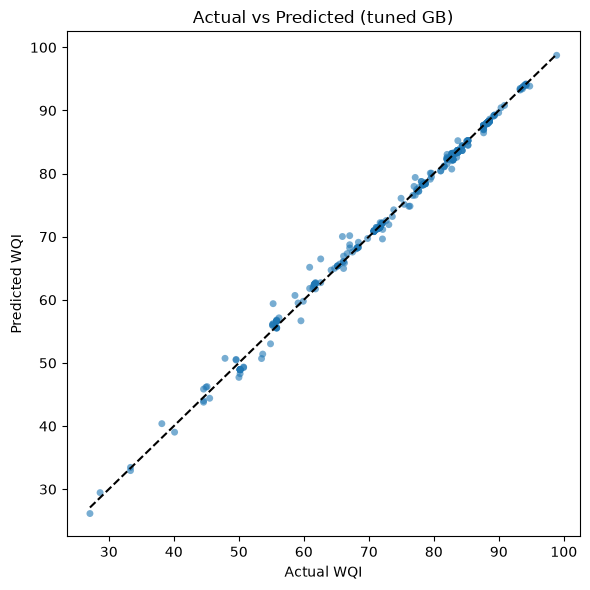

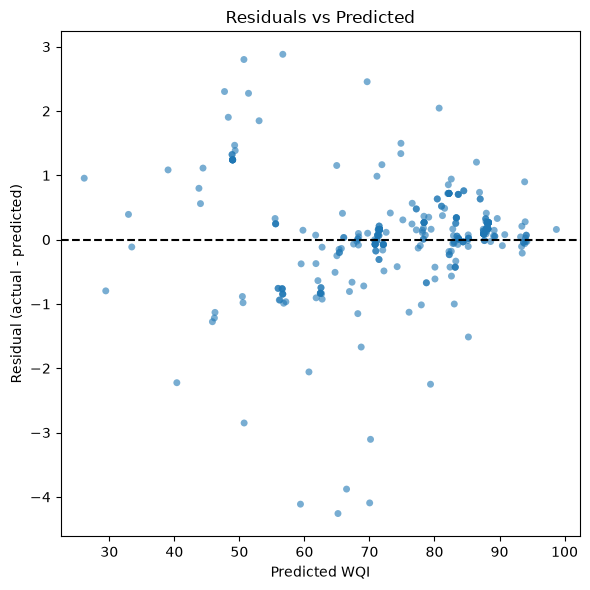

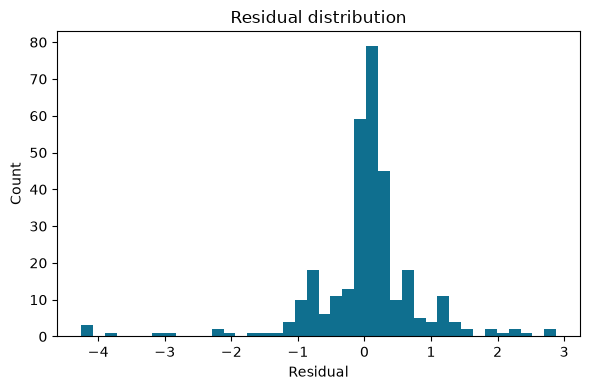

Residual: mean 0.0363, std 0.8508, MAE 0.5115, max|resid| 4.2589

Performance across actual-WQI quintiles:
                count       MAE  mean_signed_err      RMSE
bin                                                       
(27.099, 61.8]     65  1.159164        -0.101619  1.422768
(61.8, 71.7]       65  0.377680        -0.216126  0.876729
(71.7, 82.76]      62  0.506387         0.101344  0.720525
(82.76, 87.66]     65  0.285296         0.213698  0.448167
(87.66, 98.9]      62  0.215305         0.194506  0.271240


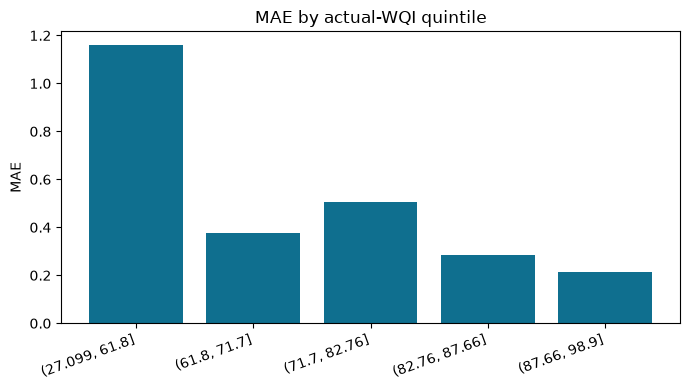


Mean |error| far vs near a rating-band boundary (2% relative window):
                   count      mean
far from boundary    156  0.432752
near boundary        163  0.586961

Tuned-GB feature importance:
TOTAL COLIFORM (MPN/100ml)Mean      5.113406e-01
D.O. (mg/l)                         3.053475e-01
PH                                  1.120184e-01
B.O.D. (mg/l)                       7.048698e-02
CONDUCTIVITY (µmhos/cm)             8.057559e-04
NITRATENAN N+ NITRITENANN (mg/l)    7.207601e-07


In [6]:
# ============================================================
# ERROR ANALYSIS (Part 4) - plots generated live; nothing is invented.
# ============================================================
resid = y_test.values - y_pred

# Actual vs predicted
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6, edgecolors="none", s=25)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "--", color="k")
plt.xlabel("Actual WQI"); plt.ylabel("Predicted WQI")
plt.title("Actual vs Predicted (tuned GB)")
plt.tight_layout(); plt.show()

# Residual vs predicted
plt.figure(figsize=(6, 6))
plt.axhline(0, color="k", ls="--")
plt.scatter(y_pred, resid, alpha=0.6, edgecolors="none", s=25)
plt.xlabel("Predicted WQI"); plt.ylabel("Residual (actual - predicted)")
plt.title("Residuals vs Predicted")
plt.tight_layout(); plt.show()

# Residual distribution
plt.figure(figsize=(6, 4))
plt.hist(resid, bins=40, color="#0f6f8f")
plt.xlabel("Residual"); plt.ylabel("Count"); plt.title("Residual distribution")
plt.tight_layout(); plt.show()
print("Residual: mean %.4f, std %.4f, MAE %.4f, max|resid| %.4f"
      % (resid.mean(), resid.std(), np.mean(np.abs(resid)), np.max(np.abs(resid))))

# Performance across the target range (quintiles of actual WQI)
tmp = pd.DataFrame({"actual": y_test.values, "pred": y_pred})
tmp["resid"] = tmp["actual"] - tmp["pred"]
tmp["abs_err"] = tmp["resid"].abs()
tmp["sq_err"] = tmp["resid"] ** 2
tmp["bin"] = pd.qcut(tmp["actual"], q=5, duplicates="drop")
bin_table = tmp.groupby("bin", observed=True).agg(
    count=("actual", "size"),
    MAE=("abs_err", "mean"),
    mse=("sq_err", "mean"),
    mean_signed_err=("resid", "mean"))
bin_table["RMSE"] = np.sqrt(bin_table["mse"])
bin_table = bin_table.drop(columns="mse")
print("\nPerformance across actual-WQI quintiles:")
print(bin_table.to_string())

plt.figure(figsize=(7, 4))
plt.bar(range(len(bin_table)), bin_table["MAE"].values, color="#0f6f8f")
plt.xticks(range(len(bin_table)), [str(i) for i in bin_table.index], rotation=20, ha="right")
plt.ylabel("MAE"); plt.title("MAE by actual-WQI quintile")
plt.tight_layout(); plt.show()

# Band-boundary analysis.
# HYPOTHESIS (to observe, NOT assert): because the label is quantised, error
# concentrates where a feature sits near a rating-band edge (a tiny change flips n_i).
EDGES = {
    "PH": [6.5, 6.7, 6.8, 7.0, 8.5, 8.6, 8.8, 9.0],
    "D.O. (mg/l)": [3.0, 4.1, 5.1, 6.0],
    "B.O.D. (mg/l)": [3, 6, 80, 125],
    FEATURES[2]: [75, 150, 225, 300],
    FEATURES[4]: [20, 50, 100, 200],
    FEATURES[5]: [5, 50, 500, 1000],
}


def near_any_boundary(row):
    for feat, edges in EDGES.items():
        v = row[feat]
        for e in edges:
            tol = 0.02 * abs(e) if e != 0 else 0.02
            if abs(v - e) <= tol:
                return True
    return False


Xt = X_test.copy()
Xt["_near"] = Xt.apply(near_any_boundary, axis=1)
Xt["_ae"] = np.abs(resid)
grp = Xt.groupby("_near")["_ae"].agg(["count", "mean"])
grp.index = ["far from boundary", "near boundary"]
print("\nMean |error| far vs near a rating-band boundary (2% relative window):")
print(grp.to_string())

# Tuned-GB feature importance (consistency check against the index weights).
imp = pd.Series(best_model.feature_importances_, index=FEATURES).sort_values(ascending=False)
print("\nTuned-GB feature importance:")
print(imp.to_string())

In [7]:
# ============================================================
# STACKING EXPERIMENT (Part 5)
# ============================================================
# PRE-REGISTERED DECISION RULE (fixed BEFORE running, to prevent cherry-picking).
# Adopt stacking ONLY if BOTH hold:
#   (a) test RMSE improves over tuned GB by >= 5% relative, AND
#   (b) CV R2 mean gain over tuned GB exceeds the tuned-GB CV R2 std.
# The deployed model is NOT changed by this notebook regardless of the outcome.

stack = StackingRegressor(
    estimators=[
        ("dt", DecisionTreeRegressor(random_state=RANDOM_STATE)),
        ("rf", RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE)),
        ("gb", best_model),          # tuned GB as a base member (strongest single in)
    ],
    final_estimator=Ridge(),
    cv=cv,                          # out-of-fold base predictions for the meta-learner
    n_jobs=-1,
)
stack.fit(X_train, y_train)         # <-- X_train only; test set never used

stack_test = score(y_test, stack.predict(X_test))
stack_cv = cv_metrics(stack, "Stacking", n_jobs=1)   # n_jobs=1: avoid nested oversubscription

rmse_gain = (tuned_test["RMSE"] - stack_test["RMSE"]) / tuned_test["RMSE"]
cv_r2_gain = stack_cv["CV R2"] - tuned_cv["CV R2"]

results_df = pd.concat([results_df, pd.DataFrame([{
    "Model": "Stacking (DT+RF+GBtuned / Ridge)", **stack_cv,
    "Test MAE": stack_test["MAE"], "Test RMSE": stack_test["RMSE"], "Test R2": stack_test["R2"],
    "Skill (1-RMSE/RMSE_base)": 1 - stack_test["RMSE"] / baseline_rmse,
}])], ignore_index=True)
print("Full comparison (single held-out test set):")
print(results_df.to_string(index=False))

print("\nStacking decision (pre-registered):")
print("  test RMSE gain vs tuned GB : %.2f%%  (threshold 5.00%%)" % (rmse_gain * 100))
print("  CV R2 gain vs tuned GB     : %.5f  (tuned-GB CV R2 std: %.5f)"
      % (cv_r2_gain, tuned_cv["CV R2 std"]))
adopt = (rmse_gain >= 0.05) and (cv_r2_gain > tuned_cv["CV R2 std"])
print("  => ADOPT stacking:", bool(adopt))
print("  (Deployed model unchanged either way; see README before changing artifacts.)")

Full comparison (single held-out test set):
                           Model    CV MAE   CV RMSE  CV RMSE std     CV R2  CV R2 std  Test MAE  Test RMSE   Test R2  Skill (1-RMSE/RMSE_base)
           Mean baseline (Dummy) 11.188078 14.181016     0.312276 -0.009282   0.007001 11.545930  13.912189 -0.005830                  0.000000
               Linear Regression  8.032420  9.433346     0.124109  0.552314   0.028914  8.038684   9.329377  0.547687                  0.329410
                   Decision Tree  0.758620  2.490367     0.249858  0.968582   0.006368  0.717743   2.194243  0.974979                  0.842279
                   Random Forest  0.824091  2.117410     0.509150  0.976434   0.010788  0.539877   1.315366  0.991009                  0.905452
     Gradient Boosting (untuned)  0.660524  1.321815     0.372114  0.990654   0.005161  0.479315   0.785109  0.996797                  0.943567
       Gradient Boosting (tuned)  0.648521  1.172072     0.303129  0.992743   0.003618  0.51

## Interpretation (Part 6)

**The WQI target is computed deterministically from the exact same six inputs the model
receives.** The validity gate proves this: `0` of the `1593` unique input vectors map to
more than one WQI value. Therefore this task is **formula approximation, not independent
prediction of real-world water quality.** A learned model can at best *recover* the closed-
form index; it **cannot and must not be claimed to "outperform" the WQI formula** (the formula
*is* the ground-truth label; perfect recovery is R² = 1 and there is nothing beyond it).

What these experiments can legitimately support:

1. **Recovery skill vs a trivial baseline.** The mean-baseline row sets the reference point;
   the tuned GB's skill `1 - RMSE/RMSE_base` measures how much of the index it reproduces.
2. **Where the residual error lives.** The quintile table and the boundary analysis show
   whether error concentrates at rating-band edges (a genuine, explainable consequence of the
   five-level quantisation) or drifts across the target range (heteroscedasticity).
3. **SHAP / importance consistency, not discovery.** The importance ordering tracks the known
   unit weights (Total Coliform and DO carry the largest weight, 0.281 each), so it is reported
   as *consistency with the index definition*, not as discovery of hidden physical drivers.
4. **A rigorous protocol** (frozen split, shared CV folds, tuning isolated from test,
   pre-registered stacking rule) that a reviewer can re-run.

What must NOT be claimed: that the model predicts true water quality better than prior work,
that a high R² demonstrates forecasting skill, or that stacking "beats" the WQI equation.

The **StackingRegressor** above is adopted only if it clears the pre-registered bar (test RMSE
≥ 5% relative improvement over tuned GB **and** CV-R² gain exceeding the CV std). Because the
target is deterministic, a marginal or absent gain is the expected and honest outcome; the
deployed model is **not** changed by this notebook regardless of the result.

In [8]:
# ============================================================
# RUN MANIFEST
# ============================================================
print("=" * 60)
print("RUN MANIFEST")
print("=" * 60)
print("N samples           :", len(wqi_df))
print("Features (n)        :", len(FEATURES))
print("Feature order       :", FEATURES)
print("Train / Test        :", len(X_train), "/", len(X_test))
print("random_state        :", RANDOM_STATE)
print("sklearn / shap      :", sklearn.__version__, "/", shap.__version__)
print("Target max possible :", 100 * WEIGHT_SUM)

print("\nHeadline test metrics (this run; single held-out test set):")
for _, r in results_df.iterrows():
    print("  %-34s MAE %.4f  RMSE %.4f  R2 %.4f"
          % (r["Model"], r["Test MAE"], r["Test RMSE"], r["Test R2"]))

print("\nPreviously reported tuned-GB (NOT reused as a result here):")
print("  MAE 0.51155  RMSE 0.85160  R2 0.99623")
print("  -> re-measured in the 'Gradient Boosting (tuned)' row above.")

RUN MANIFEST
N samples           : 1593
Features (n)        : 6
Feature order       : ['D.O. (mg/l)', 'PH', 'CONDUCTIVITY (µmhos/cm)', 'B.O.D. (mg/l)', 'NITRATENAN N+ NITRITENANN (mg/l)', 'TOTAL COLIFORM (MPN/100ml)Mean']
Train / Test        : 1274 / 319
random_state        : 42
sklearn / shap      : 1.9.0 / 0.52.0
Target max possible : 99.80000000000001

Headline test metrics (this run; single held-out test set):
  Mean baseline (Dummy)              MAE 11.5459  RMSE 13.9122  R2 -0.0058
  Linear Regression                  MAE 8.0387  RMSE 9.3294  R2 0.5477
  Decision Tree                      MAE 0.7177  RMSE 2.1942  R2 0.9750
  Random Forest                      MAE 0.5399  RMSE 1.3154  R2 0.9910
  Gradient Boosting (untuned)        MAE 0.4793  RMSE 0.7851  R2 0.9968
  Gradient Boosting (tuned)          MAE 0.5115  RMSE 0.8516  R2 0.9962
  Stacking (DT+RF+GBtuned / Ridge)   MAE 0.4989  RMSE 0.8486  R2 0.9963

Previously reported tuned-GB (NOT reused as a result here):
  MAE 0.51155 